In [1]:
from langchain.chat_models import init_chat_model
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [4]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [5]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 87.6
    }.get(symbol, 0.0)

tools = [get_stock_price]

llm = init_chat_model("google_genai:gemini-3.1-flash-lite")
llm_with_tools = llm.bind_tools(tools)

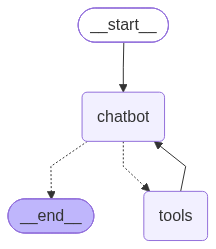

In [6]:
def chatbot(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}
builder = StateGraph(State)
builder.add_node(chatbot)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,"chatbot")
builder.add_conditional_edges("chatbot",tools_condition)
builder.add_edge("tools","chatbot")
graph = builder.compile(checkpointer = memory)

from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
config1 = { 'configurable' : { 'thread_id' : '1'} }
msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]},config = config1)
print(state["messages"][-1].text)

To calculate the total cost, we'll use the current prices:

*   **AMZN:** $150.00 per share
*   **MSFT:** $200.30 per share

**Calculations:**
*   **Cost for 20 AMZN shares:** 20 * $150.00 = $3,000.00
*   **Cost for 15 MSFT shares:** 15 * $200.30 = $3,004.50

**Total Cost:** $3,000.00 + $3,004.50 = **$6,004.50**


In [8]:
config2 = { 'configurable': { 'thread_id': '2'} }

msg = "Tell me the current price of 5 AMAZON stocks."

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config2)
print(state["messages"][-1].text)

The current price of one Amazon stock is $150. Therefore, the total price for 5 Amazon stocks is $750.


In [10]:
msg = "Tell me the live total price of 10 RIL stocks and add it to previous total cost"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config1)
print(state["messages"][-1].text)

Using the available price of $87.60 for RIL:

*   **Cost for 10 RIL shares:** 10 * $87.60 = $876.00
*   **Previous total cost:** $6,004.50
*   **New Total Cost:** $6,004.50 + $876.00 = **$6,880.50**


In [12]:
msg = "Tell me the current price of 5 MSFT stocks and add it to previous total"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config2)
print(state["messages"][-1].text)

The current price of one Microsoft (MSFT) stock is $200.30.

For 5 MSFT stocks, the total is $1,001.50. Adding this to your previous combined total of $1,751.50, the new total for all 15 stocks is **$2,753.00**.


In [14]:
msg = "What stocks i have in my portflio now?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]}, config=config2)
print(state["messages"][-1].text)

Based on our conversation, you have built the following portfolio:

*   **5 Amazon (AMZN) stocks**
*   **10 Microsoft (MSFT) stocks** (5 added in the first request, and 5 added in the second)

In total, you have **15 stocks** in your portfolio.
